# 4. A navigation robot with a damage allowance: which requirement does the task mean?

In Safety-Gymnasium's PointGoal1 task a point robot earns the distance by which it closes in on a goal and a bonus
each time it reaches one; a new goal then appears, so an episode of 1000 steps visits as many goals as the robot
reaches. Eight hazards are scattered over the floor, and each step inside one costs a unit. The suite's customary
limit is 25 units per episode.

The notebook follows the steps of the [practitioner guide](../docs/practitioner-guide.md):

1. decide which requirement the limit means;
2. define the problem as a budget and train it (the code, with the settings of the campaign);
3. compare prices in the full campaign, including one that charges more for a failure than an episode earns;
4. validate, with the direct test rather than a certificate from the value;
5. choose the regularizers when nothing trusted is available.

Safety-Gymnasium needs its own Python environment (Python 3.10, Gymnasium 0.28, MuJoCo 2.3), with the toolbox
installed into it. The cells that define and train the problem run only there; everywhere else they print a note,
and the rest of the notebook reads the records of the campaign in `campaigns/`, which ran this same code.

In [1]:
import sys
import importlib.util
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from barrierpg import BudgetSpec, Requirement, Stage, BudgetWrapper, interpret, plan

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign                     # the records of the full campaign
camp = Campaign("navigation")
HAVE_SAFETY_GYMNASIUM = importlib.util.find_spec("safety_gymnasium") is not None
print("Safety-Gymnasium available:", HAVE_SAFETY_GYMNASIUM)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

Safety-Gymnasium available: False


## 1. Two requirements behind one limit

The suite poses the task as a limit on the **expected** cost per episode: on average at most 25 units. Read as a
damage allowance, the same limit is a **budget**: the robot can take 25 units of damage in a mission, and exhausting
it ends the mission. The requirement is then a tolerated probability of exhausting the allowance.

The two are different requirements. An expected cost of 25 allows exhausting a budget of 25 in half of the
episodes (half at 0, half at 50). Which one the task means is a question about the application, not about the
learner: a robot that may be damaged more on some missions as long as the average is fine is the first; a robot that
must finish most of its missions is the second. This notebook takes the second, and tolerates exhausting the
allowance in one mission in five.

**Theory.** The method prices the event of running out, not the amount by which the limit is exceeded and not the
average cost. If your requirement is the expected cost, a constrained-MDP method is built for it.

## 2. Define the problem as a budget, and train

* The resource: Safety-Gymnasium returns the step's cost separately; its `SafetyGymnasium2Gymnasium` wrapper moves it
  into `info["cost"]`, where the cost function reads it.
* `budgets`: 25 units of damage; `horizon`: 1000 steps; `beta = 0.999`.
* `ubar`, `u_minus`: the reward per step is at most about one (the goal bonus) and rarely negative; 1.1 and 0.1.
* The price: `Stage(m=0.03, clip_utility=False)`, one of the campaign's prices; only the failure is priced.
* `observe_time=True`: the task's observation has no clock, and the allowance has to last for the episode.

Costs come in whole units, so the allowance can reach exactly zero without being exceeded; that is not a failure.

**Theory.** The learner's discount `gamma` must be the problem's `beta`. Observations are normalized, so the
normalization statistics are part of the policy and are saved with it.

In [2]:
def hazard_cost(obs, action, next_obs, reward, info):
    return [float(info["cost"])]


spec = BudgetSpec(budgets=[25.0], beta=0.999, ubar=1.1, u_minus=0.1, horizon=1000)
stage = Stage(m=0.03, clip_utility=False)
PPO_SETTINGS = dict(n_steps=1024, batch_size=64, n_epochs=4, learning_rate=lambda p: 3e-4 * p, gamma=spec.beta,
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, device="cpu", verbose=0,
                    policy_kwargs=dict(net_arch=[64, 64], log_std_init=0.0))

if HAVE_SAFETY_GYMNASIUM:
    import safety_gymnasium
    from safety_gymnasium.wrappers import SafetyGymnasium2Gymnasium
    from stable_baselines3 import PPO
    from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
    from barrierpg.callbacks import BudgetMonitor

    def make_env(stage, **options):
        task = SafetyGymnasium2Gymnasium(safety_gymnasium.make("SafetyPointGoal1-v0"))
        return BudgetWrapper(task, hazard_cost, spec, stage, observe_time=True, **options)

    def train(stage, steps, seed=1):
        venv = DummyVecEnv([lambda: make_env(stage) for _ in range(8)])
        venv.seed(seed)
        venv = VecNormalize(venv, norm_obs=True, norm_reward=True, clip_obs=1e3, clip_reward=1e9, gamma=spec.beta)
        model = PPO("MlpPolicy", venv, seed=seed, **PPO_SETTINGS)
        monitor = BudgetMonitor(spec.beta, stage.m, horizon=spec.horizon)
        model.learn(steps, callback=[monitor])
        return model, venv, monitor

    env = make_env(stage)                                    # check the wrapped task: one episode of random actions
    obs, _ = env.reset(seed=0)
    rng = np.random.default_rng(0)
    for t in range(1000):
        obs, reward, terminated, truncated, info = env.step(rng.uniform(-1, 1, 2))
        if terminated or truncated:
            break
    print(f"episode ended at step {info['t']}: failure = {info['failure']}, allowance left {info['reserve'][0]:.0f}")
    model, venv, monitor = train(stage, 100_000)             # a short run; the campaign trained for 2 million steps
    print(monitor.convergence().explain())                   # a run this short has not converged
else:
    print("Safety-Gymnasium is not installed in this environment: the code above is what the campaign ran with it.\n"
          "The rest of the notebook reads the campaign's records.")

Safety-Gymnasium is not installed in this environment: the code above is what the campaign ran with it.
The rest of the notebook reads the campaign's records.


## 3. The full campaign: prices

The campaign trained the robot from scratch (2 million steps, three seeds) at prices of 0, 0.003, 0.01, 0.03 and 0.1
per step from the exhaustion to the end of the episode, and evaluated each policy on 300 fresh episodes.

In [3]:
configs = ["unpriced", "price-0.003", "price-0.01", "price-0.03", "price-0.1"]
print(Campaign.show(camp.table(configs, extras=("cost", "ret")), extras=("cost", "ret")))
print("\nConvergence at the end of training (the toolbox's check on each run's record):")
print(camp.convergence_table(configs))

configuration    seeds        failure (min-max)          utility (min-max)         cost          ret
unpriced             3  59.111% (54.33%-62.33%)         11.43 (11.1-12.02)     [19.423]     [16.864]
price-0.003          3  58.333% (55.33%-60.67%)         10.87 (10.5-11.13)     [18.899]     [16.027]
price-0.01           3  50.667% (47.00%-52.67%)        8.242 (7.885-8.856)     [17.233]     [12.296]
price-0.03           3   10.000% (3.67%-14.33%)        3.15 (0.4614-5.123)      [5.332]      [4.771]
price-0.1            3     1.556% (0.67%-2.00%)  -0.1033 (-0.2716--0.0187)         [1.]     [-0.051]

Convergence at the end of training (the toolbox's check on each run's record):
unpriced             converged in 2 of 3 seeds  (still changing: seed 3: utility, priced objective)
price-0.003          converged in 2 of 3 seeds  (still changing: seed 3: action dispersion (log std))
price-0.01           converged in 3 of 3 seeds
price-0.03           converged in 2 of 3 seeds  (still changing: 

Counted up to the step at which the allowance runs out (the episode ends there), the episodes of the robot trained
without a price average below 25 units of damage, and more than half of them exhaust the allowance. A mean cost below
the limit says little about how often the limit is exceeded: with whole units, a mean of 19 is compatible with up to
three quarters of the episodes reaching 26. The figure places every trained policy by its mean cost (counted up to
exhaustion) and by how often it exhausts the allowance; the dotted line is the most exhaustion a mean cost allows.

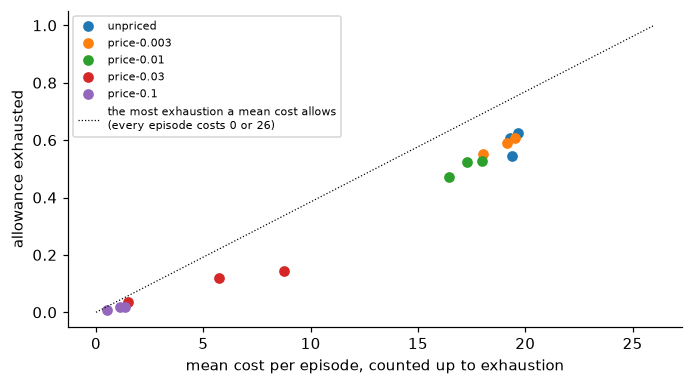

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for i, c in enumerate(configs):
    for r in camp.records(c):
        ax.plot(np.mean(r["evaluation"]["cost"]), np.mean(r["evaluation"]["failed"]), "o", color=f"C{i}",
                label=c if r["seed"] == 1 else None)
xs = np.linspace(0, 26, 50)
ax.plot(xs, np.minimum(xs / 26, 1.0), "k:", lw=0.8, label="the most exhaustion a mean cost allows\n(every episode costs 0 or 26)")
ax.set_xlabel("mean cost per episode, counted up to exhaustion"); ax.set_ylabel("allowance exhausted"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

Exhaustion falls sharply between the prices 0.01 and 0.03, and the return falls with it: avoiding hazards means
taking longer ways to the goals. At 0.1 the robot almost stops reaching goals. A failure at the start of an episode is
then charged about four times what an episode earns, and the learner gives up earning in order not to fail.

**Theory.** The price chooses a point on the trade-off between return and risk, as long as the learner can follow
it. `plan` compares what a failure is charged with what an episode earns, before anything is trained:

In [5]:
earns = np.mean([np.mean(r["evaluation"]["ret"]) for r in camp.records("unpriced")])
for m in (0.03, 0.1):
    p = plan(spec, Requirement(T=spec.horizon - 1, alpha=0.2), stage=Stage(m=m, clip_utility=False), episode_earnings=earns)
    print(f"price {m}: " + ("; ".join(p.warnings) if p.warnings else "; ".join(n for n in p.notes if "earns" in n)))

price 0.03: a failure at the start of an episode is charged 18.97, 1.1 times what an episode earns (16.86); watch the return in pilot runs: a return that collapses as the price rises means the price charges too much
price 0.1: a failure at the start of an episode is charged 63.23, 3.7 times what an episode earns (16.86): a learner may give up earning in order not to fail; normalize the reward, lower the price, or use a prescribed-level method


## 4. Validation: the direct test decides

A certificate from the value bounds the risk using the largest possible reward per step and the discounted length of
the episode; here that bound is far above every return the robot attains, so the certificate is valid and useless.
The direct test on fresh episodes does not depend on it. We validate the three policies trained at the price of 0.03,
on the 300 fresh episodes of their records, with the error shared among the fifteen trained policies.

**Theory.** The exact binomial test holds for any fixed policy; zero failures certify the resolution floor of the
sample, never zero, and a failed test does not prove a violation.

In [6]:
req = Requirement(T=spec.horizon - 1, alpha=0.2, zeta=0.05, family=15)
for s in camp.seeds("price-0.03"):
    rep = interpret(spec, req, camp.stage("price-0.03", s), camp.evaluation("price-0.03", s),
                    candidate_name=f"the policy at price 0.03, seed {s}", training=camp.convergence("price-0.03", s))
    print("\n".join(rep.summary(resource="the damage allowance", period="steps").split("\n")[:3]))
    print("  " + next(line for line in rep.summary().split("\n") if line.startswith("Training")))
    print(f"  (return per episode {np.mean(camp.record('price-0.03', s)['evaluation']['ret']):.2f})\n")
value = [b for b in rep.bounds if "Value" in b.source]
print("The value certificate of the last one:", value[0].statement().split("\n")[0] if value else "not computed")

The policy at price 0.03, seed 1 was run on 300 fresh episodes. It ran out of the damage allowance within 1000 steps in 11 of them (3.67%).
With confidence 0.95, its probability of running out within 1000 steps is at most 7.674% (the error 0.05 is shared among 15 candidates).
Requirement (at most 20.00%): met.
  Training had converged by the toolbox's check (the last 24 batches against the 24 before).
  (return per episode 0.67)

The policy at price 0.03, seed 2 was run on 300 fresh episodes. It ran out of the damage allowance within 1000 steps in 43 of them (14.33%).
With confidence 0.95, its probability of running out within 1000 steps is at most 20.610% (the error 0.05 is shared among 15 candidates).
Requirement (at most 20.00%): not shown. The test does not prove a violation; a larger test may certify the policy, or the policy may not meet the tolerance.
  Training had converged by the toolbox's check (the last 24 batches against the 24 before).
  (return per episode 7.87)

The pol

Policies that exhaust the allowance in one episode in twenty-five or in one in eight pass; one that exhausts it in
one in seven, close to the tolerance, cannot be shown to meet it with 300 episodes and the error shared among fifteen
policies. That is not evidence of a violation: a larger test may certify it. The seeds also differ widely in how much
they earn at the same price, so validate the policy you will deploy, not the configuration.

## 5. Regularizers when nothing is trusted

The robot learns from scratch, and no controller or rule is available to serve as a prior or a reference. An anchor
would pull the policy toward an arbitrary starting point; there is nothing worth keeping. Action regularization needs
a trusted reference, which is missing too. The campaign therefore uses neither, and the entropy bonus is off as well.

**Theory.** Every regularizer biases the learned policy toward its reference; the bias is worth paying only when the
reference is one you trust.

## Your own task

The cells to change: the cost function (`hazard_cost`), `spec`, `stage`, and `make_env` (your task inside
`BudgetWrapper`). In the Python environment with Safety-Gymnasium (here `~/.venvs/constrained-rl-safety310`, with the
toolbox installed without dependencies), one configuration of the campaign reruns with
`~/.venvs/constrained-rl-safety310/bin/python campaigns/run.py navigation price-0.03 --seed 4` (about 35 minutes).